In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/Nassau Candy Distributor.csv")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  str    
 2   Order Date      10194 non-null  str    
 3   Ship Date       10194 non-null  str    
 4   Ship Mode       10194 non-null  str    
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  str    
 7   City            10194 non-null  str    
 8   State/Province  10194 non-null  str    
 9   Postal Code     10194 non-null  str    
 10  Division        10194 non-null  str    
 11  Region          10194 non-null  str    
 12  Product ID      10194 non-null  str    
 13  Product Name    10194 non-null  str    
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null  float64
dt

In [3]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)
df["Ship Date"] = pd.to_datetime(df["Ship Date"], dayfirst=True)
df["Lead Time"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Lead Time"].describe()

count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Lead Time, dtype: float64

In [6]:
df["Ship Mode"].value_counts()

Ship Mode
Standard Class    6120
Second Class      1979
First Class       1548
Same Day           547
Name: count, dtype: int64

In [9]:
df["Division"].value_counts()


Division
Chocolate    9844
Other         310
Sugar          40
Name: count, dtype: int64

In [10]:
raw = pd.read_csv("../data/raw/Nassau Candy Distributor.csv")
raw[["Order Date", "Ship Date", "Ship Mode"]].head(10)

,Order Date,Ship Date,Ship Mode
0,03-01-2024,30-06-2026,Standard Class
1,04-01-2024,01-07-2026,Standard Class
2,04-01-2024,01-07-2026,Standard Class
3,04-01-2024,01-07-2026,Standard Class
4,05-01-2024,05-07-2026,Standard Class
5,06-01-2024,03-07-2026,Standard Class
6,06-01-2024,03-07-2026,Standard Class
7,06-01-2024,30-06-2026,First Class
8,06-01-2024,03-07-2026,Standard Class
9,06-01-2024,03-07-2026,Standard Class


the date ranges:

In [11]:
print(df["Order Date"].min(), df["Order Date"].max())
print(df["Ship Date"].min(), df["Ship Date"].max())

2024-01-02 00:00:00 2025-12-31 00:00:00
2026-06-30 00:00:00 2030-06-28 00:00:00


lead time by ship mode:

In [12]:
df.groupby("Ship Mode")["Lead Time"].describe()

,count,mean,std,min,25%,50%,75%,max
Ship Mode,,,,,,,,
First Class,1548.0,1338.275840,265.632140,905.0,1270.0,1272.0,1637.0,1638.0
Same Day,547.0,1333.442413,253.813374,904.0,1269.0,1269.0,1635.0,1636.0
Second Class,1979.0,1323.845376,261.813569,906.0,1271.0,1273.0,1637.0,1640.0
Standard Class,6120.0,1314.334641,262.400116,908.0,1273.0,1274.0,1639.0,1642.0


Does lead time vary by region?

In [13]:
df.groupby("Region")["Lead Time"].agg(["count", "mean", "std"])

,count,mean,std
Region,,,
Atlantic,2986,1322.745144,256.541810
Gulf,1620,1311.374691,264.727855
Interior,2335,1323.091221,262.693597
Pacific,3253,1322.194897,266.470647


Does it change over time?

In [14]:
df.groupby(df["Order Date"].dt.to_period("Q"))["Lead Time"].mean()

Order Date
2024Q1    1084.460573
2024Q2    1100.263220
2024Q3    1094.098207
2024Q4    1093.971893
2025Q1    1491.596266
2025Q2    1468.822581
2025Q3    1474.372902
2025Q4    1482.439158
Freq: Q-DEC, Name: Lead Time, dtype: float64

In [15]:
df["Product Name"].unique()

<ArrowStringArray>
[       'Wonka Bar - Milk Chocolate', 'Wonka Bar - Triple Dazzle Caramel',
 'Wonka Bar - Nutty Crunch Surprise',    'Wonka Bar -Scrumdiddlyumptious',
         'Wonka Bar - Fudge Mallows',                         'Wonka Gum',
                         'Kazookles',                'Lickable Wallpaper',
              'Fizzy Lifting Drinks',                       'Laffy Taffy',
                         'SweeTARTS',                             'Nerds',
                       'Hair Toffee',            'Everlasting Gobstopper',
                           'Fun Dip']
Length: 15, dtype: str

Add the Factory column

In [16]:
factory_map = {
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Wonka Bar - Fudge Mallows": "Lot's O' Nuts",
    "Wonka Bar -Scrumdiddlyumptious": "Lot's O' Nuts",
    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Triple Dazzle Caramel": "Wicked Choccy's",
    "Laffy Taffy": "Sugar Shack",
    "SweeTARTS": "Sugar Shack",
    "Nerds": "Sugar Shack",
    "Fun Dip": "Sugar Shack",
    "Fizzy Lifting Drinks": "Sugar Shack",
    "Everlasting Gobstopper": "Secret Factory",
    "Hair Toffee": "The Other Factory",
    "Lickable Wallpaper": "Secret Factory",
    "Wonka Gum": "Secret Factory",
    "Kazookles": "The Other Factory",
}

df["Factory"] = df["Product Name"].map(factory_map)
df["Factory"].isnull().sum()

np.int64(0)

Add the factory coordinates

In [17]:
factory_coords = {
    "Lot's O' Nuts": (32.881893, -111.768036),
    "Wicked Choccy's": (32.076176, -81.088371),
    "Sugar Shack": (48.11914, -96.18115),
    "Secret Factory": (41.446333, -90.565487),
    "The Other Factory": (35.1175, -89.971107),
}

df["Factory Lat"] = df["Factory"].map(lambda f: factory_coords[f][0])
df["Factory Lon"] = df["Factory"].map(lambda f: factory_coords[f][1])
df.groupby("Factory")["Lead Time"].agg(["count", "mean"])

,count,mean
Factory,,
Lot's O' Nuts,5692,1321.228742
Secret Factory,217,1321.870968
Sugar Shack,33,1340.030303
The Other Factory,100,1280.280000
Wicked Choccy's,4152,1321.082129


Check the customer locations

In [18]:
print(df["Country/Region"].value_counts())
print(df["State/Province"].nunique())
print(sorted(df["State/Province"].unique()))

Country/Region
United States    9994
Canada            200
Name: count, dtype: int64
59
['Alabama', 'Alberta', 'Arizona', 'Arkansas', 'British Columbia', 'California', 'Colorado', 'Connecticut', 'Delaware', 'District of Columbia', 'Florida', 'Georgia', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Manitoba', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Brunswick', 'New Hampshire', 'New Jersey', 'New Mexico', 'New York', 'Newfoundland and Labrador', 'North Carolina', 'North Dakota', 'Nova Scotia', 'Ohio', 'Oklahoma', 'Ontario', 'Oregon', 'Pennsylvania', 'Prince Edward Island', 'Quebec', 'Rhode Island', 'Saskatchewan', 'South Carolina', 'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 'Washington', 'West Virginia', 'Wisconsin', 'Wyoming']


Add customer locations

In [20]:
state_coords = {
    "Alabama": (32.8067, -86.7911), "Arizona": (34.1682, -111.9309),
    "Arkansas": (34.9697, -92.3731), "California": (36.1162, -119.6816),
    "Colorado": (39.0598, -105.3111), "Connecticut": (41.5978, -72.7554),
    "Delaware": (39.3185, -75.5071), "District of Columbia": (38.8974, -77.0268),
    "Florida": (27.7663, -81.6868), "Georgia": (33.0406, -83.6431),
    "Idaho": (44.2405, -114.4788), "Illinois": (40.3495, -88.9861),
    "Indiana": (39.8494, -86.2583), "Iowa": (42.0115, -93.2105),
    "Kansas": (38.5266, -96.7265), "Kentucky": (37.6681, -84.6701),
    "Louisiana": (31.1695, -91.8678), "Maine": (44.6939, -69.3819),
    "Maryland": (39.0639, -76.8021), "Massachusetts": (42.2302, -71.5301),
    "Michigan": (43.3266, -84.5361), "Minnesota": (45.6945, -93.9002),
    "Mississippi": (32.7416, -89.6787), "Missouri": (38.4561, -92.2884),
    "Montana": (46.9219, -110.4544), "Nebraska": (41.1254, -98.2681),
    "Nevada": (38.3135, -117.0554), "New Hampshire": (43.4525, -71.5639),
    "New Jersey": (40.2989, -74.5210), "New Mexico": (34.8405, -106.2485),
    "New York": (42.1657, -74.9481), "North Carolina": (35.6301, -79.8064),
    "North Dakota": (47.5289, -99.7840), "Ohio": (40.3888, -82.7649),
    "Oklahoma": (35.5653, -96.9289), "Oregon": (44.5720, -122.0709),
    "Pennsylvania": (40.5908, -77.2098), "Rhode Island": (41.6809, -71.5118),
    "South Carolina": (33.8569, -80.9450), "South Dakota": (44.2998, -99.4388),
    "Tennessee": (35.7478, -86.6923), "Texas": (31.0545, -97.5635),
    "Utah": (40.1500, -111.8624), "Vermont": (44.0459, -72.7107),
    "Virginia": (37.7693, -78.1700), "Washington": (47.4009, -121.4905),
    "West Virginia": (38.4912, -80.9545), "Wisconsin": (44.2685, -89.6165),
    "Wyoming": (42.7560, -107.3025),
    "Alberta": (53.9333, -116.5765), "British Columbia": (53.7267, -127.6476),
    "Manitoba": (53.7609, -98.8139), "New Brunswick": (46.5653, -66.4619),
    "Newfoundland and Labrador": (53.1355, -57.6604),
    "Nova Scotia": (44.6820, -63.7443), "Ontario": (51.2538, -85.3232),
    "Prince Edward Island": (46.5107, -63.4168),
    "Quebec": (52.9399, -73.5491), "Saskatchewan": (52.9399, -106.4509),
}

df["Dest Lat"] = df["State/Province"].map(lambda s: state_coords[s][0] if s in state_coords else None)
df["Dest Lon"] = df["State/Province"].map(lambda s: state_coords[s][1] if s in state_coords else None)
df["Dest Lat"].isnull().sum()

np.int64(0)

Calculate the distance

In [21]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Earth radius in km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

df["Distance KM"] = haversine(df["Factory Lat"], df["Factory Lon"], df["Dest Lat"], df["Dest Lon"])
df["Distance KM"].describe()

count    10194.000000
mean      1996.591370
std       1081.175631
min        143.825279
25%       1008.219033
50%       1801.583121
75%       3079.150107
max       4796.579547
Name: Distance KM, dtype: float64

Check whether distance matters

In [22]:
df[["Lead Time", "Distance KM", "Sales", "Units", "Gross Profit", "Cost"]].corr()["Lead Time"]

Lead Time       1.000000
Distance KM     0.013945
Sales          -0.005438
Units          -0.006702
Gross Profit   -0.003305
Cost           -0.007846
Name: Lead Time, dtype: float64

Remove the year effect and recheck

In [25]:
df["Order Year"] = df["Order Date"].dt.year
df["Lead Time Adj"] = df["Lead Time"] - df.groupby("Order Year")["Lead Time"].transform("mean")

df[["Lead Time Adj", "Distance KM", "Units", "Sales"]].corr()["Lead Time Adj"]

Lead Time Adj    1.000000
Distance KM      0.010330
Units           -0.005450
Sales           -0.011417
Name: Lead Time Adj, dtype: float64

Look at the distribution

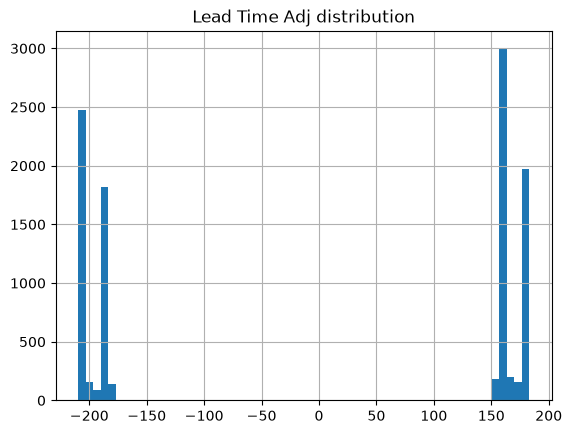

,count,mean,std,min,25%,50%,75%,max
Order Year,,,,,,,,
2024,4181.0,2.784389e-14,182.501417,-190.018417,-186.018417,174.981583,178.981583,182.981583
2025,6013.0,-9.680303e-14,181.553830,-209.558290,-205.558290,158.441710,160.441710,163.441710


In [26]:
df["Lead Time Adj"].hist(bins=60)
plt.title("Lead Time Adj distribution")
plt.show()

df.groupby("Order Year")["Lead Time Adj"].describe()

Find what splits the two groups

In [27]:
df["Cluster"] = (df["Lead Time Adj"] > 0).astype(int)
df["Order Month"] = df["Order Date"].dt.month

pd.crosstab(df["Order Month"], [df["Order Year"], df["Cluster"]])

Order Year  2024      2025     
Cluster        0    1    0    1
Order Month                    
1             84   64   95  161
2             46   64   83  107
3            159  141  166  245
4            135  160  171  204
5            132  150  229  247
6            136  138  205  246
7            143  140  205  230
8            158  162  179  223
9            273  295  366  465
10           168  167  199  309
11           320  324  370  460
12           297  325  366  482

Remove the shift

In [28]:
df["Block"] = ((df["Lead Time"] - df["Lead Time"].min()) / 365).round().astype(int)
df["Lead Time Clean"] = df["Lead Time"] - df.groupby("Block")["Lead Time"].transform("min")

print(df["Block"].value_counts())
df.groupby("Ship Mode")["Lead Time Clean"].describe()

Block
1    4764
2    3379
0    2051
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
Ship Mode,,,,,,,,
First Class,1548.0,2.547804,0.887849,1.0,2.0,3.0,3.0,5.0
Same Day,547.0,0.383912,0.533457,0.0,0.0,0.0,1.0,2.0
Second Class,1979.0,3.572006,1.280342,1.0,2.0,3.0,5.0,6.0
Standard Class,6120.0,5.315850,1.128344,3.0,4.0,5.0,6.0,11.0


In [29]:
print(df[["Lead Time Clean", "Distance KM"]].corr())
print(df.groupby("Region")["Lead Time Clean"].agg(["count", "mean"]))
print(df.groupby("Factory")["Lead Time Clean"].agg(["count", "mean"]))

                 Lead Time Clean  Distance KM
Lead Time Clean         1.000000     0.008374
Distance KM             0.008374     1.000000
          count      mean
Region                   
Atlantic   2986  4.239116
Gulf       1620  4.297531
Interior   2335  4.382441
Pacific    3253  4.273901
                   count      mean
Factory                           
Lot's O' Nuts       5692  4.263176
Secret Factory       217  4.092166
Sugar Shack           33  4.666667
The Other Factory    100  3.980000
Wicked Choccy's     4152  4.347303


Save the cleaned data

In [30]:
df.to_csv("../data/processed/nassau_clean.csv", index=False)
print(df.shape)

(10194, 31)


Making first chart

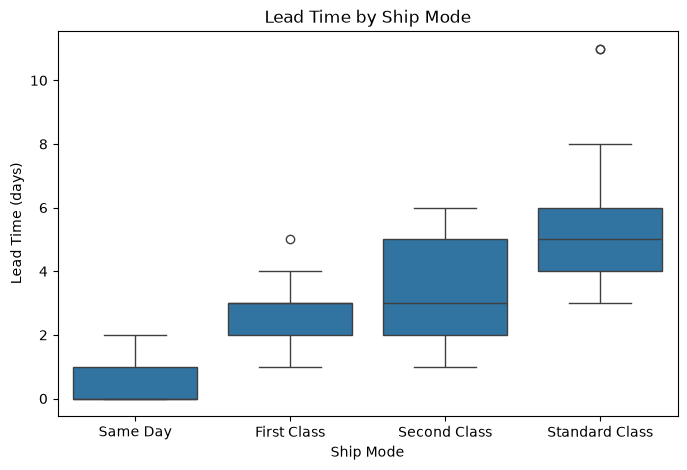

In [31]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Ship Mode", y="Lead Time Clean",
            order=["Same Day", "First Class", "Second Class", "Standard Class"])
plt.title("Lead Time by Ship Mode")
plt.ylabel("Lead Time (days)")
plt.savefig("../reports/lead_time_by_ship_mode.png", dpi=150, bbox_inches="tight")
plt.show()

Chart lead time by region

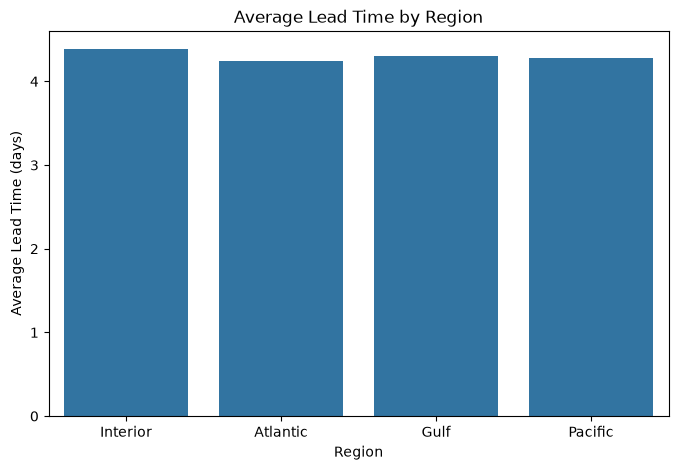

In [32]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Region", y="Lead Time Clean", errorbar=None)
plt.title("Average Lead Time by Region")
plt.ylabel("Average Lead Time (days)")
plt.savefig("../reports/lead_time_by_region.png", dpi=150, bbox_inches="tight")
plt.show()

Chart profit by factory

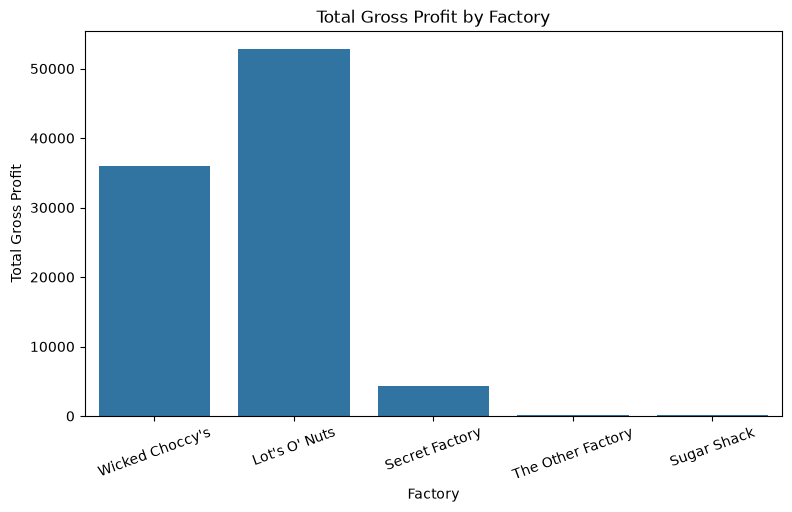

In [33]:
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="Factory", y="Gross Profit", estimator="sum", errorbar=None)
plt.title("Total Gross Profit by Factory")
plt.ylabel("Total Gross Profit")
plt.xticks(rotation=20)
plt.savefig("../reports/profit_by_factory.png", dpi=150, bbox_inches="tight")
plt.show()